# **Exercice 1**

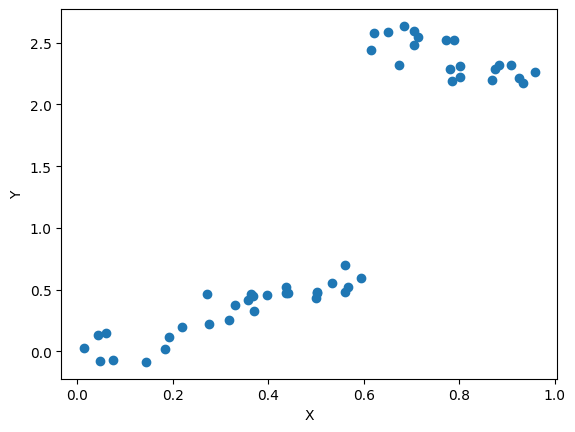

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

n = 50
np.random.seed(1234) #random fixé
X = np.random.uniform(0, 1, n)

np.random.seed(5678)
# Generation de Y avec une relation non-lineaire par morceaux
Y = 1 * X * (X <= 0.6) + (-1 * X + 3.2) * (X > 0.6) + np.random.normal(0, 0.1, n)

data1 = pd.DataFrame({'X': X, 'Y': Y})

# Visualisation
plt.scatter(data1['X'], data1['Y'])
plt.xlabel('X')
plt.ylabel('Y')
plt.show()


**Question 1:**

À l’aide de la classe DecisionTreeRegressor du module sklearn.tree, construire un arbre
permettant d’expliquer Y par X. Rappel : sous scikit-learn, la matrice des caractéristiques doit
être en 2D. Vous pouvez utiliser data1[['X']] au lieu de data1['X'].


In [ ]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor() #pour que l'arbre soit joli, max_depth=1 mais on la enlever la pour que le schéma d'après soit pas hideux
model.fit(data1[['X']], data1['Y'])

DecisionTreeRegressor()

**Question 2:**

Représenter l’arbre avec la fonction plot_tree de sklearn.tree.

[Text(0.4865451388888889, 0.9444444444444444, 'X <= 0.605\nsquared_error = 1.062\nsamples = 50\nvalue = 1.191'),
 Text(0.23177083333333334, 0.8333333333333334, 'X <= 0.246\nsquared_error = 0.047\nsamples = 29\nvalue = 0.33'),
 Text(0.3591579861111111, 0.8888888888888888, 'True  '),
 Text(0.11805555555555555, 0.7222222222222222, 'X <= 0.188\nsquared_error = 0.01\nsamples = 9\nvalue = 0.046'),
 Text(0.08333333333333333, 0.6111111111111112, 'X <= 0.068\nsquared_error = 0.008\nsamples = 7\nvalue = 0.014'),
 Text(0.05555555555555555, 0.5, 'X <= 0.054\nsquared_error = 0.008\nsamples = 4\nvalue = 0.058'),
 Text(0.041666666666666664, 0.3888888888888889, 'X <= 0.045\nsquared_error = 0.007\nsamples = 3\nvalue = 0.028'),
 Text(0.027777777777777776, 0.2777777777777778, 'X <= 0.029\nsquared_error = 0.003\nsamples = 2\nvalue = 0.08'),
 Text(0.013888888888888888, 0.16666666666666666, 'squared_error = 0.0\nsamples = 1\nvalue = 0.03'),
 Text(0.041666666666666664, 0.16666666666666666, 'squared_error = 0

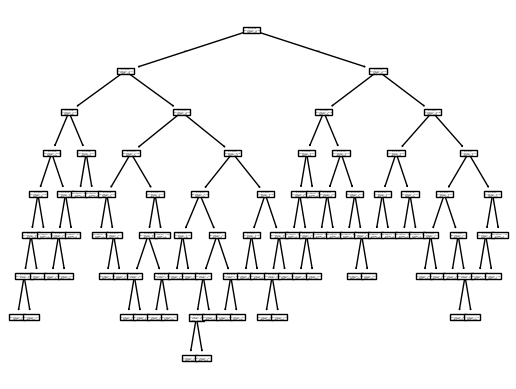

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree


plot_tree(model, feature_names=['X'])

**Question 3:**

Écrire l’estimateur mathématique associé à l’arbre.

voir note TP2 propre mais en gros ^y = 2.38 U{X>=0.605} + 0.33 U{X<0.605}

**Question 4:**

Ajouter sur le graphe de la question 1 la partition définie par l’arbre ainsi que la courbe des
valeurs prédites (la fonction en escalier).

0.6050104796886444


<>:17: SyntaxWarning: invalid escape sequence '\('
<>:26: SyntaxWarning: invalid escape sequence '\('
<>:17: SyntaxWarning: invalid escape sequence '\('
<>:26: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_2305/3669904800.py:17: SyntaxWarning: invalid escape sequence '\('
  label="Données observées (\(Y\) vs \(X\))",
/tmp/ipykernel_2305/3669904800.py:26: SyntaxWarning: invalid escape sequence '\('
  label="Valeurs prédites \(\hat{f}(X)\)",


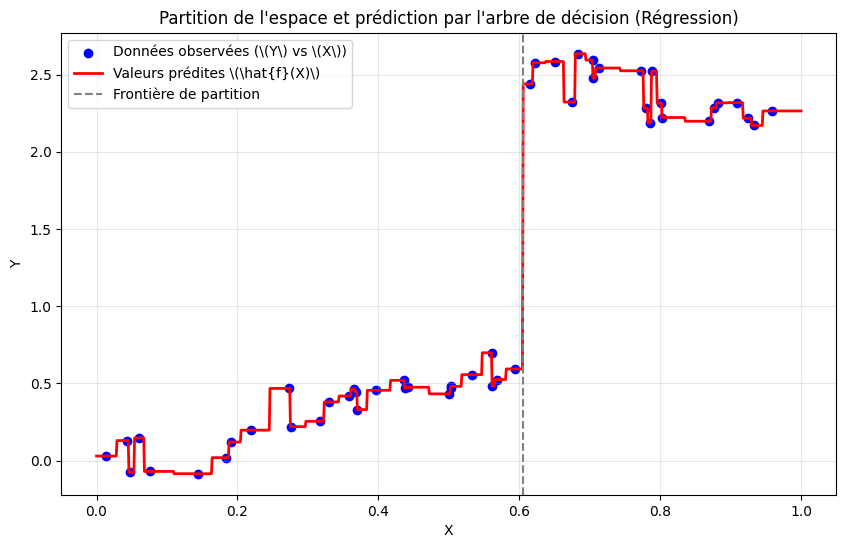

In [ ]:
X_grid = pd.DataFrame({"X": np.linspace(0, 1, 1000)})
Y_pred = model.predict(X_grid)

# Extraire les seuils de coupure (partition)
thresholds = model.tree_.threshold[0]
print(thresholds)


# 3. Tracé du graphique
plt.figure(figsize=(10, 6))

# Nuage de points initial
plt.scatter(
    data1["X"],
    data1["Y"],
    color="blue",
    label="Données observées (\(Y\) vs \(X\))",
)

# Courbe en escalier des prédictions
plt.plot(
    X_grid["X"],
    Y_pred,
    color="red",
    linewidth=2,
    label="Valeurs prédites \(\hat{f}(X)\)",
)

# Lignes verticales représentatives de la partition

plt.axvline(
    x=thresholds,
    color="gray",
    linestyle="--",
    label="Frontière de partition",
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title(
    "Partition de l'espace et prédiction par l'arbre de décision (Régression)"
)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# **Exercice 2:**

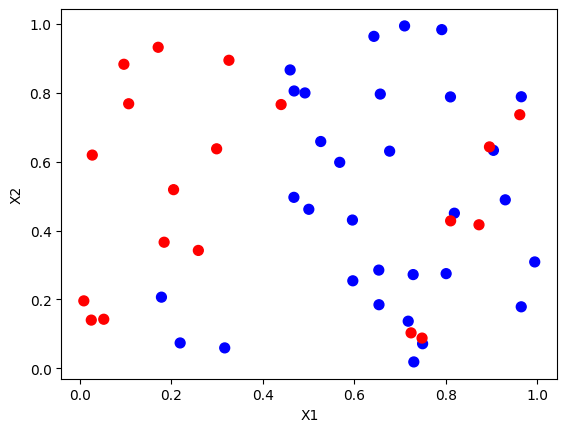

In [ ]:
n = 50
np.random.seed(12345)
X1 = np.random.uniform(0, 1, n)

np.random.seed(5678)
X2 = np.random.uniform(0, 1, n)

Y = np.zeros(n)

np.random.seed(54321)

mask1 = (X1 <= 0.45)
Y[mask1] = np.random.binomial(1, 0.85, np.sum(mask1))

np.random.seed(52432)
mask2 = (X1 > 0.45)
Y[mask2] = np.random.binomial(1, 0.15, np.sum(mask2))

data2 = pd.DataFrame({'X1': X1, 'X2': X2, 'Y': Y})

# Visualisation (les couleurs representent les classes)
plt.scatter(data2['X1'], data2['X2'], c=data2['Y'], cmap='bwr', s=50)
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()


**Question 1:**

Construire un arbre de classification (via DecisionTreeClassifier) permettant d’expliquer Y
par X1 et X2. Représenter l’arbre et identifier l’éventuel problème (observez la complexité et la
profondeur de l’arbre généré par défaut).


In [ ]:
from sklearn.tree import DecisionTreeClassifier

model2 = DecisionTreeClassifier(max_depth=1) #pour que l'arbre soit joli, max_depth=1 mais on la enlever la pour que le schéma d'après soit pas hideux
model2.fit(data2[['X1', 'X2']], data2['Y'])


DecisionTreeClassifier(max_depth=1)

[Text(0.5, 0.75, 'X1 <= 0.45\ngini = 0.471\nsamples = 50\nvalue = [31, 19]'),
 Text(0.25, 0.25, 'gini = 0.305\nsamples = 16\nvalue = [3, 13]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.291\nsamples = 34\nvalue = [28, 6]'),
 Text(0.625, 0.5, '  False')]

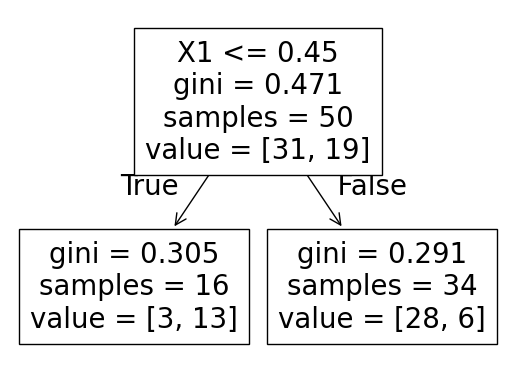

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree


plot_tree(model2, feature_names=['X1', 'X2'])
